### 1️⃣ 러닝머신 워크플로우

실제 머신러닝 프로젝트에서는 바로 `fit()`을 실행하지않는다. 어떤 **문제를 해결할지 정의**하고, **데이터를 분석**하고, **학습용 데이터를 준비**하고, **모델을 평가하는 과정**이 필요하다.

이러한 과정이 러닝머신이 동작하는 워클플로우다.

공부할 때 봤던 문제를 그대로 다시 풀어서 높은 점수를 받았다고 실력이 좋다고 할 수 없다.

머신러닝도 마찬가지로 학습에 사용되지 않은 데이터로 성능을 확인해야한다.

In [15]:
# 목표 : 공부시간을 이용해서 학생의 시험 점수를 예측하는 모델 만들기
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 선형 회귀 모델
from sklearn.linear_model import LinearRegression

# 학습/테스트 데이터 분리
from sklearn.model_selection import train_test_split

# 예측 오차 평가
from sklearn.metrics import mean_absolute_error

data = {
    "study_hours": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10,
                    11, 12, 13, 14, 15, 16, 17, 18, 19, 20],
    "scores": [32, 35, 41, 39, 46, 49, 51, 57, 55, 61,
              65, 63, 70, 73, 76, 78, 81, 85, 86, 91]
}

df = pd.DataFrame(data)

데이터를 분석하기 전에 먼저 데이터 파악을 해야한다.
- 데이터의 총 갯수는 얼마정도 되는지
- 결측치, 이상치는 없는지
- 각 컬럼의 자료형은 어떻게 되는지
- 공부시간과 시험점수는 대략 어떤관계가 되는지

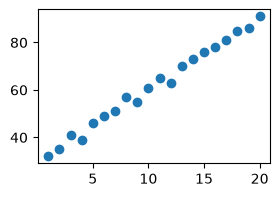

In [17]:
# 아래 시각화로 공부시간이 길어질수록 시험점수가 상승하는 경향을 확인할 수 있다.
# 어떤 모델을 사용할지 판단할 기준이 생긴다.
plt.figure(figsize=(3, 2))
plt.scatter(data=df, x="study_hours", y="scores")
plt.show()

In [20]:
# Feature(X), Target(y) 분리하기
X = df[["study_hours"]]
y = df["scores"]

# Train / Test 데이터 분리
# 모델 평가에는 학습에 사용하지 않는 Test 데이터가 필요하다 (학습 데이터 8 / 테스트 데이터 2)
# train_test_split()의 매개변수
# X : 입력특성
# y : 실제정답
# test_size=0.2 : 전체 데이터 중 20%를 테스트용으로 사용
# radom_state=42 : 무작위 분할을 재현할 수 있도록 시드고정. 42라는 숫자는 큰 의미 없다
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [18]:
# 모델 생성
model = LinearRegression()

# 학습
model.fit(X_train, y_train)

# 학습된 값 확인
print("기울기 :", model.coef_)
print("절편 :", model.intercept_)

기울기 : [2.99019756]
절편 : 30.418488915698987


In [23]:
# 테스트 데이터로 예측해보기
y_pred = model.predict(X_test)

# 에측 확인
print("실제 값 :", y_test.to_numpy())
print("예측 값 :", y_pred)

실제 값 : [32 85 78 35]
예측 값 : [33.40868647 84.24204494 78.26164983 36.39888403]


In [24]:
# 모델 성능 평가하기
# 모델 성능 평가에는 MAE(Mean Absolute Error, 평균 절대 오차)라는 지표를 사용할 수 있다.
# MAE : 실제값과 예측값의 차이를 절대값으로 바꾸고 평균을 구하는 것
mae = mean_absolute_error(y_test, y_pred)
print("MAE :", mae)

MAE : 0.9567938470818866


---
### 실습

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

data = {
    "experience": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10,
                   11, 12, 13, 14, 15],
    "salary": [2800, 3100, 3500, 3800, 4200,
               4500, 4900, 5100, 5500, 5900,
               6200, 6600, 6900, 7300, 7600]
}

df = pd.DataFrame(data)

(15, 2)
experience    0
salary        0
dtype: int64


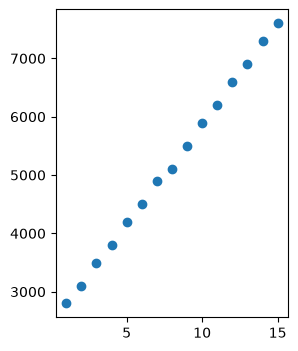

In [31]:
# 1. 데이터의 행과 열 개수를 출력해 봐.
print(df.shape)

# 2. 결측치가 있는지 확인해 봐.
print(df.isnull().sum())

# 3. 경력과 연봉의 관계를 산점도로 시각화해 봐.
plt.figure(figsize=(3, 4))
plt.scatter(data=df, x="experience", y="salary")
plt.show()

# 4. experience를 X, salary를 y로 분리해 봐.
X = df[["experience"]]
y = df["salary"]

# 5. train_test_split()을 사용해 학습 데이터 80%, 테스트 데이터 20%로 분리해 봐. random_state=42를 사용해.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [ ]:
# 6. LinearRegression 모델을 생성해 봐.
model = LinearRegression()

# 7. 학습 데이터만 사용해 모델을 학습시켜 봐.
model.fit(X_train, y_train)

# 8. 테스트 데이터의 연봉을 예측해 봐.
y_pred = model.predict(X_test)

# 9. MAE를 계산해 봐.
mae = mean_absolute_error(y_test, y_pred)

# 10. 실제 연봉, 예측 연봉, 절대 오차를 포함하는 DataFrame을 만들어 봐.
pred_df = pd.DataFrame({
    "actual": y_test.to_numpy(),
    "predicted": y_pred
})

pred_df["absolute_error"] = (
    pred_df["actual"] - pred_df["predicted"]
).abs()

print(pred_df)

26.721980771763203
   actual    predicted  absolute_error
0    5900  5876.254445       23.745555
1    6600  6564.519953       35.480047
2    2800  2779.059660       20.940340
